# gold_candidates.csv — 기초 통계량 & 결측치 EDA

- 데이터: `project/data/model_datasets/gold/gold_candidates.csv`
- 목적: (1) 데이터 구조와 기초 통계량 파악, (2) 결측치의 규모·패턴·원인(출처별 구조적 결측 여부) 시각화

## 0. 환경 설정

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

# 한글 폰트 (Windows: 맑은 고딕)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 차트 스타일: 옅은 그리드, 얇은 축
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110,
})

# 출처(source)별 고정 색상 — 순위가 아닌 출처에 색을 고정
SOURCE_ORDER = ["danawa", "zooplus", "petsathome", "petsmart", "purina_uk"]
SOURCE_COLOR = dict(zip(SOURCE_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
# 결측률(0→1) 순차 색상: 단일 hue(blue) 밝음→어두움
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. 데이터 로드 및 개요

In [2]:
DATA_PATH = Path("../data/model_datasets/gold/gold_candidates.csv")
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
df["source"] = pd.Categorical(df["source"], categories=SOURCE_ORDER)

print(f"행 수: {df.shape[0]:,} / 열 수: {df.shape[1]}")
print(f"메모리 사용량: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print(f"중복 행: {df.duplicated().sum()} / 중복 sample_id: {df['sample_id'].duplicated().sum()}")
df.head()

행 수: 4,711 / 열 수: 33
메모리 사용량: 8.2 MB
중복 행: 0 / 중복 sample_id: 0


,sample_id,group_id,source,source_file,region,currency,product_id,brand,product_name,food_type,life_stage,breed_size,ingredients,description,crude_protein,crude_fat,crude_fiber,crude_ash,moisture,calcium,phosphorus,sodium,kcal_per_kg,price_min,price_max,price_per_kg,rating,review_count,url,label_raw,label_source,label_confidence,quality_flags
0,danawa_17885090,danawa:17885090,danawa,danawa_dogfood.csv,KR,KRW,17885090,NaN,한국마즈 로얄캐닌 독 가스트로 인테스티널 로우팻 스몰독 1.5kg,건식,NaN,NaN,"닭고기, 오리고기, 과일·야채",NaN,20.000,5.000,2.800,6.800,10.500,0.840,0.640,NaN,NaN,"28,340.000",NaN,NaN,4.700,319.000,https://prod.danawa.com/info/?pcode=17885090&c...,소화·장건강,danawa_function,gold,NaN
1,danawa_45991481,danawa:45991481,danawa,danawa_dogfood.csv,KR,KRW,45991481,NaN,한국마즈 로얄캐닌 독 가스트로 인테스티널 로우팻 스몰독 3.5kg,건식,NaN,NaN,"닭고기, 오리고기, 과일·야채",NaN,20.000,5.000,2.800,6.800,10.500,0.840,0.640,NaN,NaN,"69,500.000",NaN,NaN,4.800,46.000,https://prod.danawa.com/info/?pcode=45991481&c...,소화·장건강,danawa_function,gold,NaN
2,danawa_6381618,danawa:6381618,danawa,danawa_dogfood.csv,KR,KRW,6381618,NaN,한국마즈 로얄캐닌 독 하이포알러제닉 스몰독 1kg,건식,어덜트,NaN,"닭고기, 오리고기, 돼지고기, 과일·야채",NaN,22.000,14.000,1.700,9.500,10.500,0.648,0.488,NaN,NaN,"22,740.000",NaN,NaN,4.700,557.000,https://prod.danawa.com/info/?pcode=6381618&ca...,"소화·장건강, 신장·요로건강, 치석예방·제거, 피부·모질개선",danawa_function,gold,NaN
3,danawa_6927844,danawa:6927844,danawa,danawa_dogfood.csv,KR,KRW,6927844,NaN,한국마즈 로얄캐닌 독 미니 인도어 어덜트 8.7kg,건식,어덜트,미디움(~13mm),"닭고기, 칠면조고기, 곡물, 과일·야채",NaN,19.000,12.000,2.900,6.800,11.000,0.550,0.300,NaN,NaN,"75,660.000",NaN,NaN,4.800,999.000,https://prod.danawa.com/info/?pcode=6927844&ca...,"소화·장건강, 체중관리",danawa_function,gold,NaN
4,danawa_106558997,danawa:106558997,danawa,danawa_dogfood.csv,KR,KRW,106558997,NaN,힐스 힐스 프리스크립션 다이어트 독 i/d 로우팻 다이제스티브 케어 스튜 캔 354g,습식,어덜트,NaN,"닭고기, 돼지고기, 과일·야채, 곡물",NaN,22.900,9.200,1.800,NaN,NaN,0.910,0.610,NaN,NaN,"7,760.000",NaN,NaN,4.900,23.000,https://prod.danawa.com/info/?pcode=106558997&...,"소화·장건강, 체중관리",danawa_function,gold,NaN


In [3]:
# 컬럼 정보 요약: 타입, 고유값 수, 결측 수
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
info

,dtype,non_null,missing,missing_%,n_unique
sample_id,object,4711,0,0.000,4711
group_id,object,4711,0,0.000,4711
source,category,4711,0,0.000,5
source_file,object,4711,0,0.000,5
region,object,4711,0,0.000,4
currency,object,4232,479,10.200,3
product_id,object,4711,0,0.000,4711
brand,object,2848,1863,39.500,243
product_name,object,4711,0,0.000,4466
food_type,object,4651,60,1.300,13


In [4]:
# 컬럼 그룹 정의 (이후 분석에서 공통 사용)
NUTRIENT_COLS = ["crude_protein", "crude_fat", "crude_fiber", "crude_ash", "moisture",
                 "calcium", "phosphorus", "sodium", "kcal_per_kg"]
PRICE_COLS = ["price_min", "price_max", "price_per_kg"]
REVIEW_COLS = ["rating", "review_count"]
NUMERIC_COLS = NUTRIENT_COLS + PRICE_COLS + REVIEW_COLS
CATEGORICAL_COLS = ["source", "region", "currency", "brand", "food_type", "life_stage", "breed_size",
                    "label_source", "label_confidence"]

## 2. 기초 통계량

### 2-1. 수치형 변수

In [5]:
desc = df[NUMERIC_COLS].describe().T
desc["skew"] = df[NUMERIC_COLS].skew()
desc["kurt"] = df[NUMERIC_COLS].kurt()
desc["missing_%"] = df[NUMERIC_COLS].isna().mean() * 100
desc

,count,mean,std,min,25%,50%,75%,max,skew,kurt,missing_%
crude_protein,"4,523.000",21.813,8.593,0.240,17.000,24.000,27.000,59.000,-0.282,0.002,3.991
crude_fat,"4,518.000",11.694,5.666,0.100,7.800,12.000,15.000,85.000,1.811,17.730,4.097
crude_fiber,"3,747.000",3.555,3.054,0.000,1.800,3.000,5.000,70.000,4.645,67.598,20.463
crude_ash,"3,283.000",6.084,2.904,0.070,3.000,6.500,8.000,31.000,0.080,1.020,30.312
moisture,"2,511.000",34.213,31.911,0.000,10.000,12.000,75.000,95.000,0.627,-1.549,46.699
calcium,"2,365.000",0.957,0.613,0.010,0.690,1.000,1.200,21.000,15.451,489.778,49.798
phosphorus,"2,332.000",0.714,0.606,0.000,0.490,0.700,0.950,24.000,25.114,944.109,50.499
sodium,566.000,0.290,0.178,0.030,0.190,0.280,0.360,1.200,2.004,7.635,87.986
kcal_per_kg,"1,080.000","2,919.382","1,678.565",1.170,"1,250.000","3,539.000","3,726.250","38,980.000",8.875,196.374,77.075
price_min,"4,669.000","15,346.450","29,741.636",0.790,21.990,62.490,"21,350.000","378,150.000",3.373,17.963,0.892


> ⚠️ 가격 변수는 출처마다 통화(KRW/GBP/EUR/미기재)가 섞여 있어 전체 통계량은 해석이 어렵습니다. 아래에서 통화별로 나누어 봅니다.

In [6]:
(df.assign(currency=df["currency"].fillna("(결측)"))
   .groupby("currency")[PRICE_COLS]
   .describe()
   .stack(level=0, future_stack=True)
   [["count", "mean", "50%", "min", "max"]])

count       mean        50%     min         max
currency                                                                 
(결측)     price_min      479.000     35.368     24.990   1.490     112.690
         price_max      479.000     72.088     74.990  12.480     149.990
         price_per_kg     0.000        NaN        NaN     NaN         NaN
EUR      price_min    1,082.000     45.659     36.490   0.790     209.990
         price_max    1,082.000     98.851     90.990   1.490     472.990
         price_per_kg 1,082.000      7.663      6.880   1.890      37.500
GBP      price_min    1,278.000     29.091     21.440   0.850     124.990
         price_max    1,278.000     52.941     46.410   0.990     216.990
         price_per_kg 1,274.000      6.259      5.410   1.020      62.250
KRW      price_min    1,830.000 39,097.843 28,730.000 300.000 378,150.000
         price_max        0.000        NaN        NaN     NaN         NaN
         price_per_kg     0.000        NaN        NaN     NaN         NaN

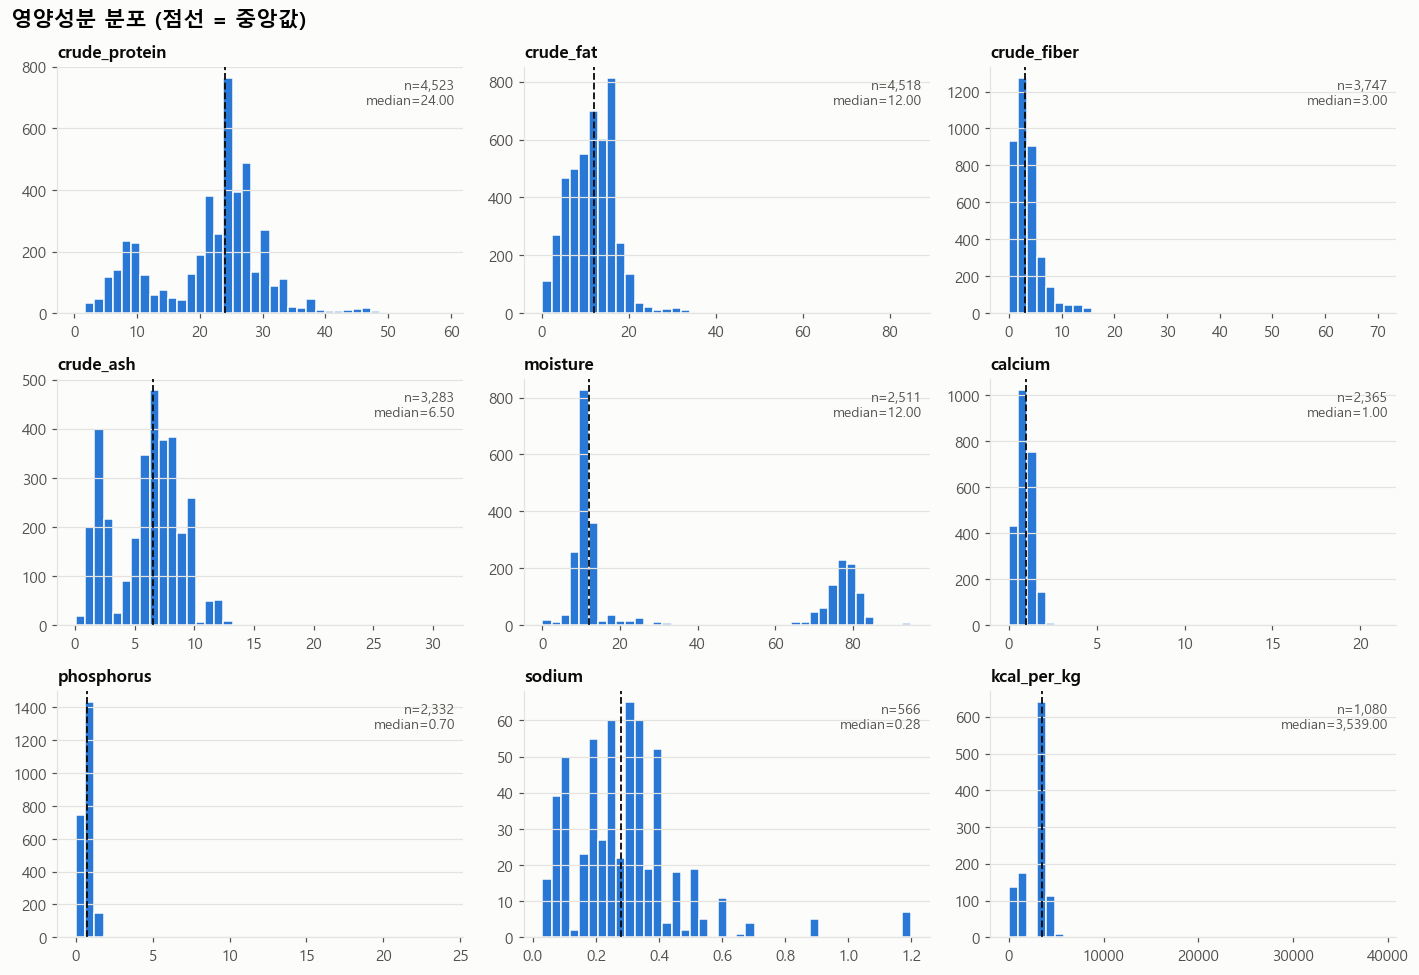

In [7]:
# 영양성분(%) 분포 — 히스토그램 + 중앙값 표시
pct_cols = ["crude_protein", "crude_fat", "crude_fiber", "crude_ash", "moisture", "calcium", "phosphorus", "sodium", "kcal_per_kg"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.flat, pct_cols):
    s = df[col].dropna()
    ax.hist(s, bins=40, color="#2a78d6", edgecolor=SURFACE, linewidth=1)
    ax.axvline(s.median(), color=INK, lw=1.2, ls="--")
    ax.set_title(col, fontsize=11)
    ax.text(0.98, 0.95, f"n={len(s):,}\nmedian={s.median():,.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=9, color=INK2)
    ax.grid(axis="x", visible=False)
fig.suptitle("영양성분 분포 (점선 = 중앙값)", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

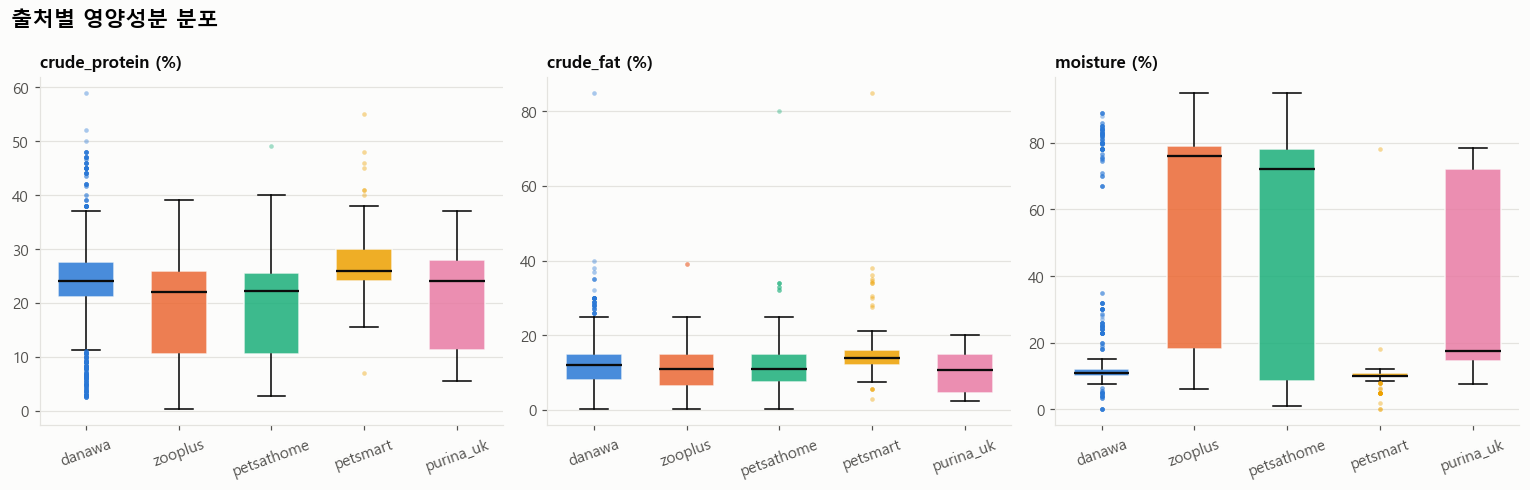

In [8]:
# 출처별 주요 영양성분 비교 (박스플롯)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
for ax, col in zip(axes, ["crude_protein", "crude_fat", "moisture"]):
    data = [df.loc[df["source"] == s, col].dropna() for s in SOURCE_ORDER]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=True,
                    medianprops=dict(color=INK, lw=1.5),
                    flierprops=dict(marker="o", markersize=3, alpha=0.4, markeredgewidth=0))
    for patch, s in zip(bp["boxes"], SOURCE_ORDER):
        patch.set(facecolor=SOURCE_COLOR[s], alpha=0.85, edgecolor=SURFACE)
    for fl, s in zip(bp["fliers"], SOURCE_ORDER):
        fl.set_markerfacecolor(SOURCE_COLOR[s])
    ax.set_xticks(range(1, len(SOURCE_ORDER) + 1), SOURCE_ORDER, rotation=20)
    ax.set_title(f"{col} (%)", fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("출처별 영양성분 분포", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

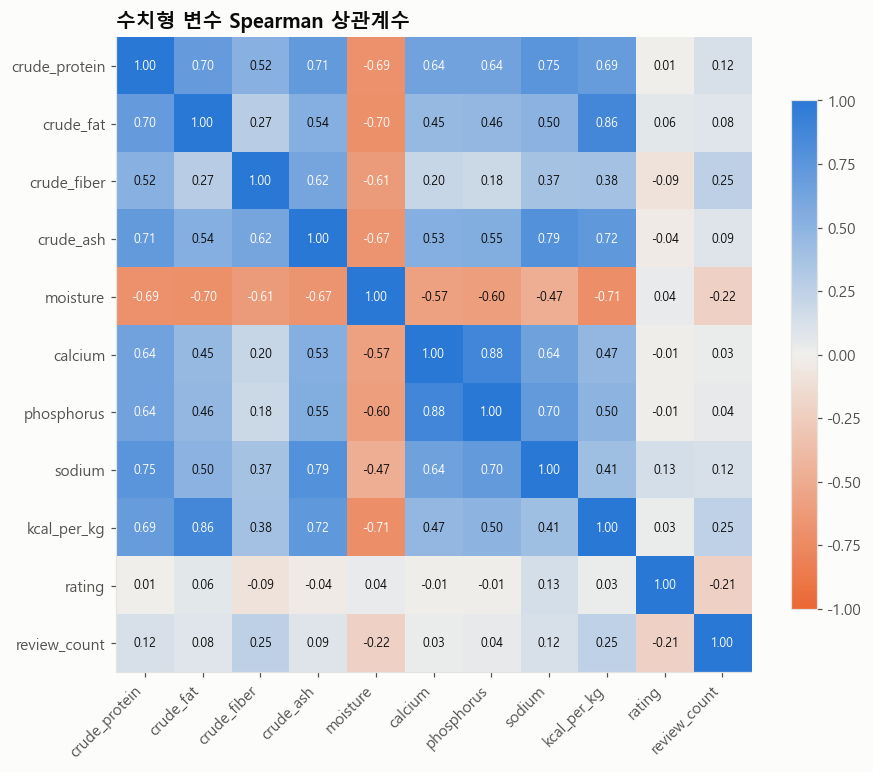

In [9]:
# 수치형 변수 간 상관관계 (pairwise complete, Spearman)
corr = df[NUTRIENT_COLS + REVIEW_COLS].corr(method="spearman")
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color=INK if abs(v) < 0.6 else "white")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("수치형 변수 Spearman 상관계수")
fig.tight_layout()
plt.show()

### 2-2. 범주형 변수

In [10]:
cat_desc = df[CATEGORICAL_COLS].astype("object").describe().T
cat_desc["missing_%"] = (df[CATEGORICAL_COLS].isna().mean() * 100).round(1)
cat_desc

,count,unique,top,freq,missing_%
source,4711,5,danawa,1830,0.000
region,4711,4,KR,1830,0.000
currency,4232,3,KRW,1830,10.200
brand,2848,243,Hill's Prescription Diet,195,39.500
food_type,4651,13,건식,2841,1.300
life_stage,4472,311,Adult,1430,5.100
breed_size,2749,178,스몰(~8mm),481,41.600
label_source,4711,5,danawa_function,1830,0.000
label_confidence,4711,1,gold,4711,0.000


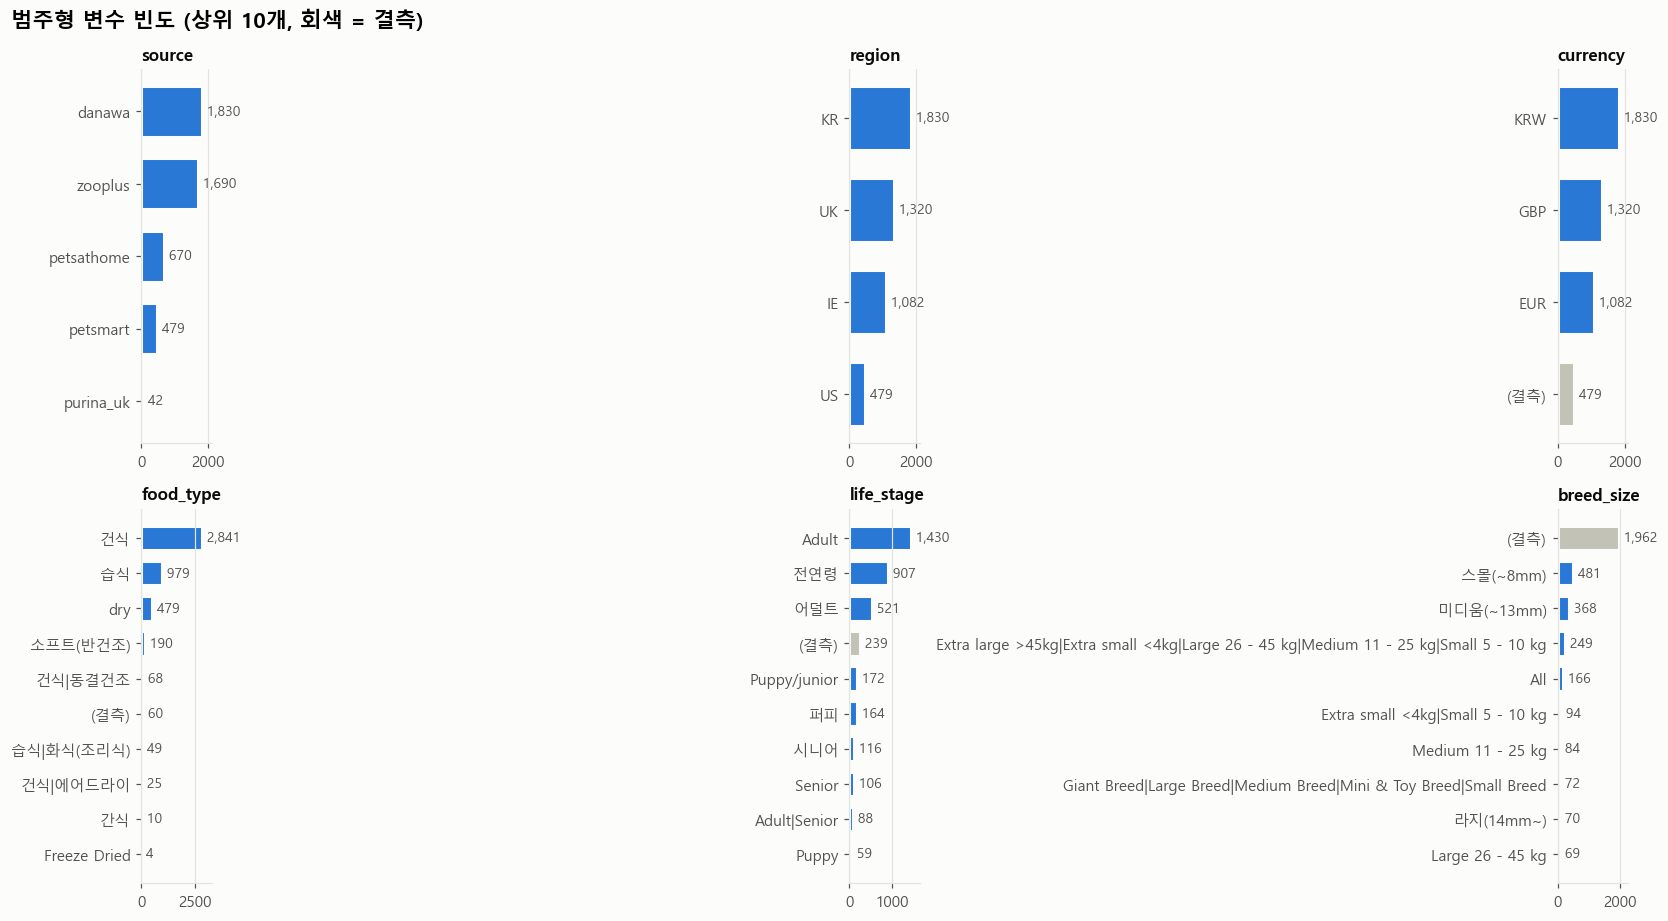

In [11]:
# 주요 범주형 변수 빈도 (결측은 별도 막대로 표시)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, col in zip(axes.flat, ["source", "region", "currency", "food_type", "life_stage", "breed_size"]):
    vc = df[col].astype("object").fillna("(결측)").value_counts().head(10).iloc[::-1]
    colors = ["#c3c2b7" if k == "(결측)" else "#2a78d6" for k in vc.index]
    ax.barh(vc.index.astype(str), vc.values, color=colors, height=0.7, edgecolor=SURFACE, linewidth=2)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=9, color=INK2)
    ax.set_title(col, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.15)
fig.suptitle("범주형 변수 빈도 (상위 10개, 회색 = 결측)", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

샘플당 라벨 수: 평균 1.58, 최대 8
고유 라벨 수: 299


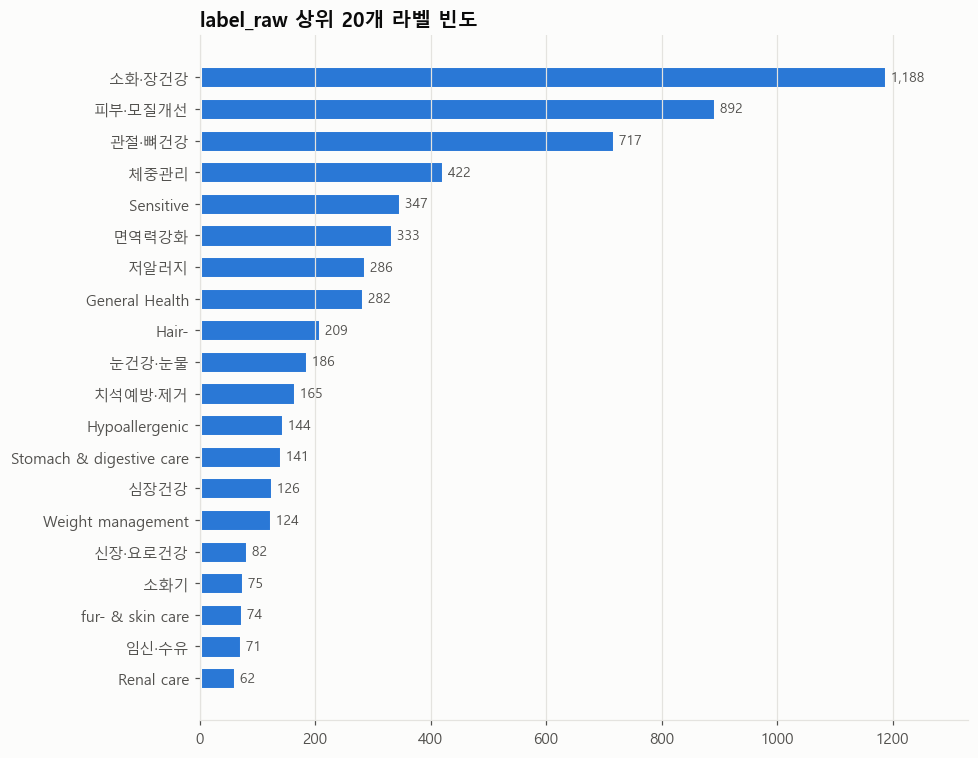

In [12]:
# 라벨(label_raw)은 콤마로 구분된 다중 라벨 → 분리하여 빈도 확인
labels = df["label_raw"].str.split(",").explode().str.strip()
n_labels = df["label_raw"].str.split(",").str.len()
print(f"샘플당 라벨 수: 평균 {n_labels.mean():.2f}, 최대 {n_labels.max()}")
print(f"고유 라벨 수: {labels.nunique()}")

top = labels.value_counts().head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color="#2a78d6", height=0.7, edgecolor=SURFACE, linewidth=2)
for y, v in enumerate(top.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9, color=INK2)
ax.set_title("label_raw 상위 20개 라벨 빈도")
ax.grid(axis="y", visible=False)
ax.margins(x=0.12)
fig.tight_layout()
plt.show()

## 3. 결측치 EDA

### 3-1. 컬럼별 결측 현황

In [13]:
missing = (pd.DataFrame({"missing": df.isna().sum(), "missing_%": df.isna().mean() * 100})
             .sort_values("missing_%", ascending=False))
print(f"결측이 있는 컬럼: {(missing['missing'] > 0).sum()} / {df.shape[1]}")
print(f"전체 셀 대비 결측 비율: {df.isna().to_numpy().mean() * 100:.1f}%")
missing[missing["missing"] > 0]

결측이 있는 컬럼: 23 / 33
전체 셀 대비 결측 비율: 24.5%


,missing,missing_%
quality_flags,4709,99.958
description,4433,94.099
sodium,4145,87.986
kcal_per_kg,3631,77.075
phosphorus,2379,50.499
price_per_kg,2355,49.989
calcium,2346,49.798
moisture,2200,46.699
breed_size,1962,41.647
price_max,1872,39.737


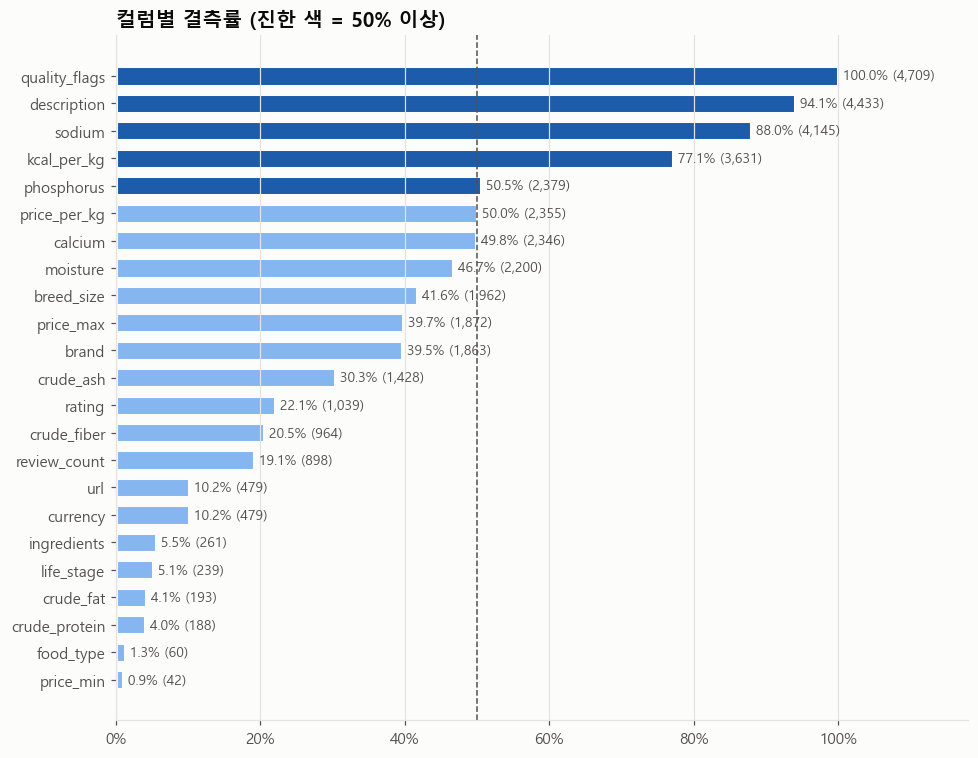

In [14]:
m = missing[missing["missing"] > 0].iloc[::-1]
# 결측률 구간별 색: 50% 이상 진한 파랑, 그 외 연한 파랑
colors = ["#1c5cab" if v >= 50 else "#86b6ef" for v in m["missing_%"]]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(m.index, m["missing_%"], color=colors, height=0.7, edgecolor=SURFACE, linewidth=2)
for y, (pct, n) in enumerate(zip(m["missing_%"], m["missing"])):
    ax.text(pct, y, f" {pct:.1f}% ({n:,})", va="center", fontsize=9, color=INK2)
ax.axvline(50, color=INK2, lw=1, ls="--")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 118)
ax.set_title("컬럼별 결측률 (진한 색 = 50% 이상)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### 3-2. 결측 매트릭스
행 = 샘플(출처 순으로 정렬), 열 = 컬럼. 색칠된 칸이 결측입니다. 가로 띠가 출처 경계와 일치하면 **출처에 따른 구조적 결측**입니다.

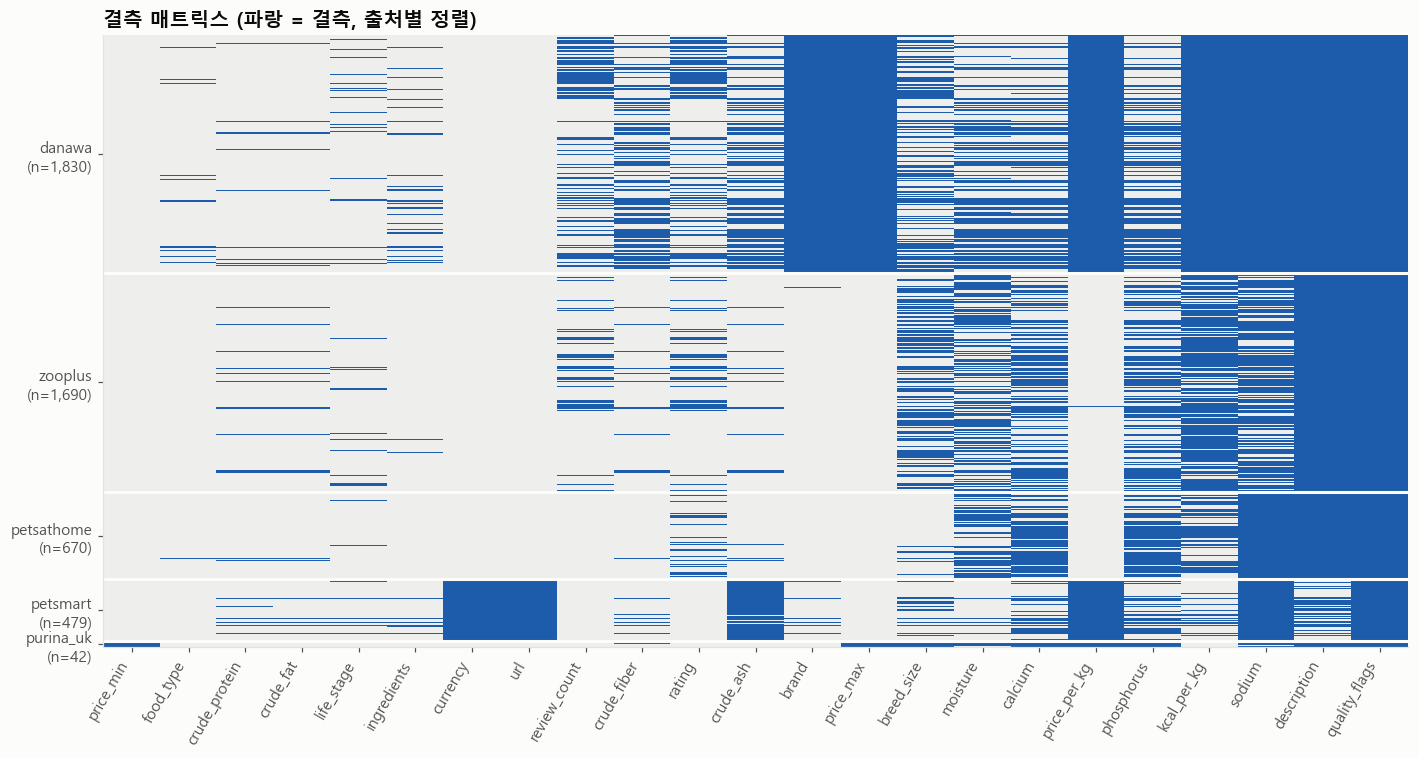

In [15]:
order = df.sort_values(["source", "sample_id"]).index
miss_cols = missing.index[missing["missing"] > 0][::-1]  # 결측률 낮은 → 높은 순
mat = df.loc[order, miss_cols].isna().to_numpy()

fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(mat, aspect="auto", interpolation="nearest", cmap=ListedColormap(["#eeeeec", "#1c5cab"]))
ax.set_xticks(range(len(miss_cols)), miss_cols, rotation=60, ha="right")
# 출처 경계선 및 라벨
counts = df["source"].value_counts().reindex(SOURCE_ORDER)
bounds = np.r_[0, counts.cumsum().to_numpy()]
for b in bounds[1:-1]:
    ax.axhline(b - 0.5, color=SURFACE, lw=2)
ax.set_yticks((bounds[:-1] + bounds[1:]) / 2, [f"{s}\n(n={n:,})" for s, n in counts.items()])
ax.grid(False)
ax.set_title("결측 매트릭스 (파랑 = 결측, 출처별 정렬)")
fig.tight_layout()
plt.show()

### 3-3. 출처별 결측률 히트맵

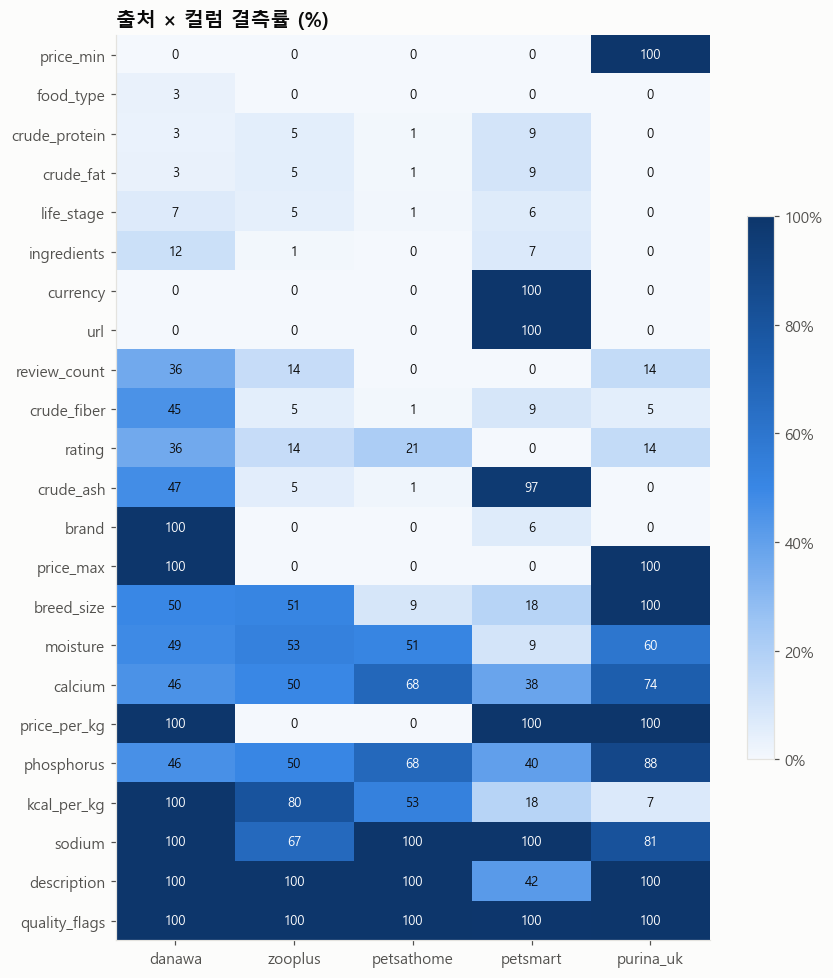

In [16]:
src_miss = (df[miss_cols].isna().groupby(df["source"], observed=True).mean() * 100).T

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(src_miss, cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(src_miss.shape[1]), src_miss.columns)
ax.set_yticks(range(src_miss.shape[0]), src_miss.index)
for i in range(src_miss.shape[0]):
    for j in range(src_miss.shape[1]):
        v = src_miss.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v >= 55 else INK)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.6, format=mtick.PercentFormatter())
ax.set_title("출처 × 컬럼 결측률 (%)")
fig.tight_layout()
plt.show()

In [17]:
# 결측 유형 분류: 출처별 결측률이 0% 또는 100%로만 구성되면 '구조적(출처 단위)' 결측
def classify(row):
    if (row == 100).all():
        return "전체 결측"
    if row.isin([0, 100]).all():
        return "구조적 (출처 단위 0/100%)"
    if (row == 100).any():
        return "혼합 (일부 출처 100% + 부분 결측)"
    return "부분 결측"

miss_type = src_miss.apply(classify, axis=1).rename("결측 유형")
fully_missing_sources = src_miss.apply(lambda r: ", ".join(r.index[r == 100]), axis=1).rename("100% 결측 출처")
pd.concat([missing.loc[miss_cols, "missing_%"], miss_type, fully_missing_sources], axis=1) \
  .sort_values("missing_%", ascending=False)

,missing_%,결측 유형,100% 결측 출처
quality_flags,99.958,혼합 (일부 출처 100% + 부분 결측),"danawa, zooplus, petsathome, purina_uk"
description,94.099,혼합 (일부 출처 100% + 부분 결측),"danawa, zooplus, petsathome, purina_uk"
sodium,87.986,혼합 (일부 출처 100% + 부분 결측),"danawa, petsmart"
kcal_per_kg,77.075,혼합 (일부 출처 100% + 부분 결측),danawa
phosphorus,50.499,부분 결측,
price_per_kg,49.989,혼합 (일부 출처 100% + 부분 결측),"danawa, petsmart, purina_uk"
calcium,49.798,부분 결측,
moisture,46.699,부분 결측,
breed_size,41.647,혼합 (일부 출처 100% + 부분 결측),purina_uk
price_max,39.737,구조적 (출처 단위 0/100%),"danawa, purina_uk"


### 3-4. 결측 간 상관관계 (Nullity Correlation)

두 컬럼의 결측 여부(0/1) 간 상관계수입니다. 1에 가까우면 함께 결측, -1에 가까우면 하나가 있으면 다른 하나는 없음을 의미합니다.

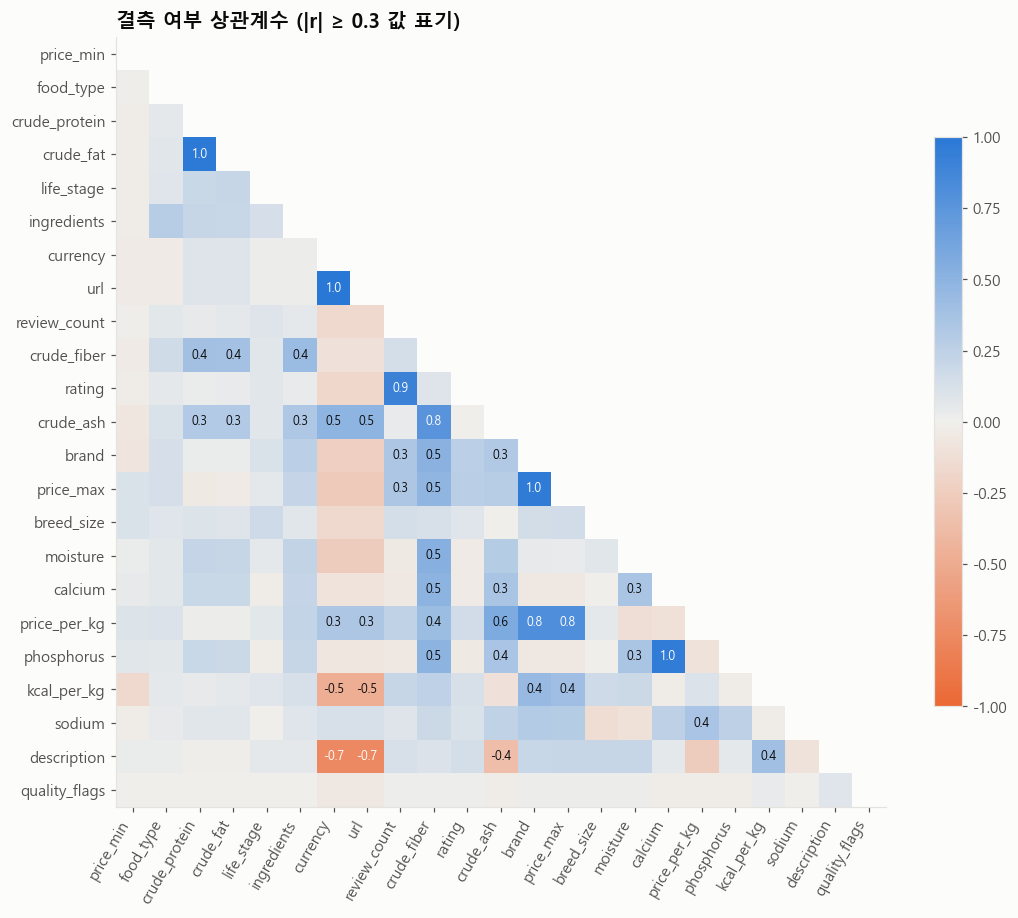

In [18]:
# 항상 결측/항상 존재하는 컬럼은 분산이 0이므로 제외
null_df = df[miss_cols].isna().astype(int)
null_df = null_df.loc[:, null_df.std() > 0]
null_corr = null_df.corr()
mask = np.triu(np.ones_like(null_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(null_corr.mask(mask), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(null_corr)), null_corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(null_corr)), null_corr.index)
for i in range(len(null_corr)):
    for j in range(i):
        v = null_corr.iat[i, j]
        if abs(v) >= 0.3:  # 의미 있는 값만 표기
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) >= 0.6 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("결측 여부 상관계수 (|r| ≥ 0.3 값 표기)")
fig.tight_layout()
plt.show()

### 3-5. 행 단위 결측 분포

count   4,711.000
mean        8.101
std         3.342
min         2.000
25%         6.000
50%         7.000
75%        10.000
max        20.000
dtype: float64


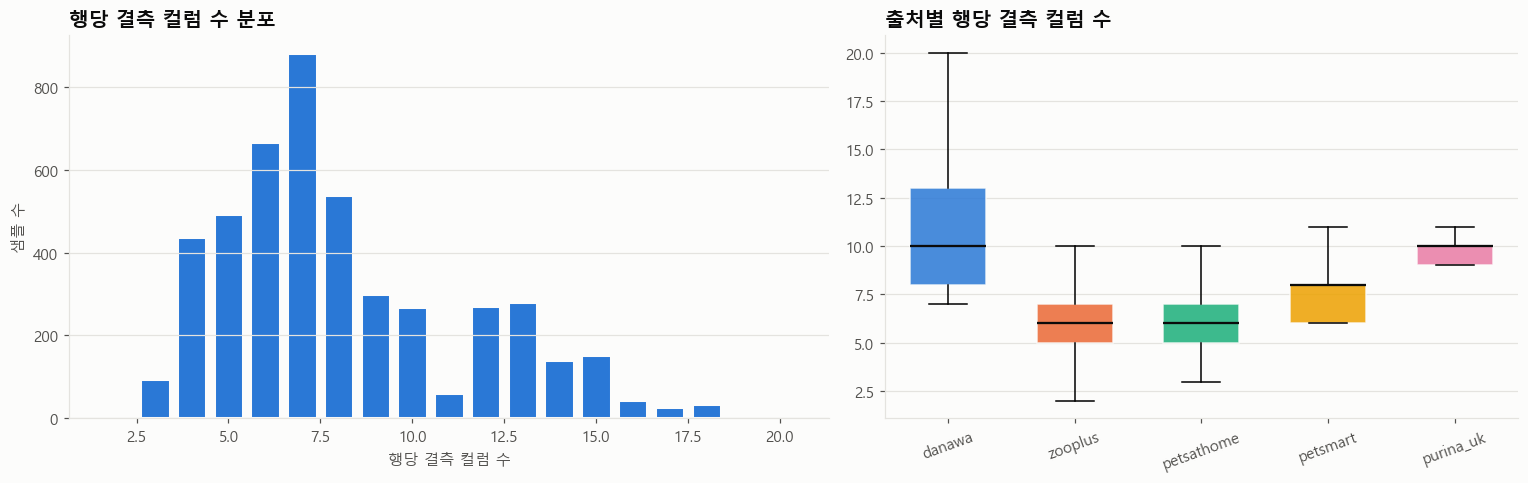

In [19]:
row_missing = df.isna().sum(axis=1)
print(row_missing.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
vc = row_missing.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="#2a78d6", width=0.8, edgecolor=SURFACE, linewidth=2)
axes[0].set_xlabel("행당 결측 컬럼 수")
axes[0].set_ylabel("샘플 수")
axes[0].set_title("행당 결측 컬럼 수 분포")
axes[0].grid(axis="x", visible=False)

data = [row_missing[df["source"] == s] for s in SOURCE_ORDER]
bp = axes[1].boxplot(data, patch_artist=True, widths=0.6, medianprops=dict(color=INK, lw=1.5),
                     flierprops=dict(marker="o", markersize=3, alpha=0.4, markeredgewidth=0))
for patch, s in zip(bp["boxes"], SOURCE_ORDER):
    patch.set(facecolor=SOURCE_COLOR[s], alpha=0.85, edgecolor=SURFACE)
axes[1].set_xticks(range(1, len(SOURCE_ORDER) + 1), SOURCE_ORDER, rotation=20)
axes[1].set_title("출처별 행당 결측 컬럼 수")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### 3-6. 영양성분 완전성 (모델 입력 관점)

확보된 핵심 성분 수,0,1,2,3,4,5,합계
source,,,,,,,
danawa,57,0,768,29,56,920,1830
zooplus,82,0,0,6,816,786,1690
petsathome,3,1,0,0,344,322,670
petsmart,39,5,0,6,415,14,479
purina_uk,0,0,0,2,23,17,42
합계,181,6,768,43,1654,2059,4711


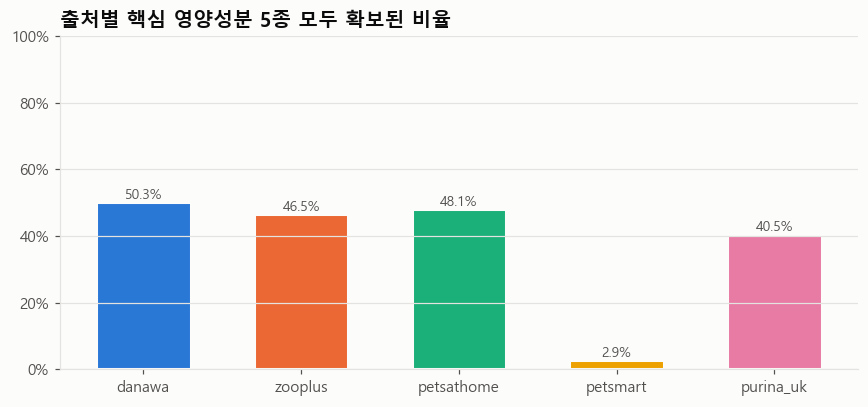

전체: 43.7% (2,059 / 4,711)


In [20]:
# 핵심 영양성분 5종(단백질·지방·섬유·회분·수분)의 동시 확보 여부
CORE = ["crude_protein", "crude_fat", "crude_fiber", "crude_ash", "moisture"]
n_core = df[CORE].notna().sum(axis=1)
tbl = pd.crosstab(df["source"], n_core, margins=True, margins_name="합계")
tbl.columns.name = "확보된 핵심 성분 수"
display(tbl)

complete_rate = (n_core == len(CORE)).groupby(df["source"], observed=True).mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(complete_rate.index, complete_rate.values,
              color=[SOURCE_COLOR[s] for s in complete_rate.index], width=0.6, edgecolor=SURFACE, linewidth=2)
for b, v in zip(bars, complete_rate.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 100)
ax.set_title(f"출처별 핵심 영양성분 {len(CORE)}종 모두 확보된 비율")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
print(f"전체: {(n_core == len(CORE)).mean() * 100:.1f}% ({(n_core == len(CORE)).sum():,} / {len(df):,})")

## 4. 요약

**기초 통계**
- 4,711개 샘플 × 33개 컬럼, `sample_id` 중복 없음. 출처는 danawa(KR) · zooplus · petsathome · petsmart(US) · purina_uk 5곳이며 `label_confidence`는 모두 `gold`입니다.
- 가격 컬럼은 KRW/GBP/EUR가 섞여 있어 그대로 비교하면 안 되며, 분석·모델링 전에 통화 정규화가 필요합니다.
- `crude_protein`과 `moisture`는 쌍봉 분포입니다. 건식(수분 약 10%)과 습식(수분 약 80%) 사료가 섞여 있기 때문이므로, 성분 비교는 건물(DM) 기준으로 환산해서 하는 것이 좋습니다.
- 이상치/단위 의심 값: `crude_fiber` > 20% (5건), `calcium`·`phosphorus` > 5% (각 2건), `kcal_per_kg` > 10,000 (1건), `kcal_per_kg` < 1,000 (146건, kcal/100g 등 단위 혼재 가능성), 5대 성분 합 > 100% (23건).

**결측치**
- `quality_flags`는 4,711건 중 2건(`species_conflict`)만 값이 있어 사실상 전체 결측입니다.
- 결측 대부분은 **출처 단위의 구조적 결측**입니다. 예: danawa의 `brand`/`price_max`/`price_per_kg`/`kcal_per_kg`/`sodium`, petsmart의 `currency`/`url`, purina_uk의 가격 전체가 해당 출처에서 100% 비어 있습니다.
- `sodium`(88%), `kcal_per_kg`(77%), `description`(94%)은 대부분의 출처에서 수집되지 않아 학습 피처로 쓰기 어렵습니다.
- 단백질·지방은 결측이 약 4%로 낮고, 섬유·회분·수분·칼슘·인은 출처에 따라 결측률 차이가 큽니다. 3-6의 완전성 표를 기준으로 피처 범위를 정하는 것이 좋습니다.

**처리 방향 제안**
1. `quality_flags`(사실상 전체 결측)와 `description`(94% 결측)은 제거하거나 별도로 관리합니다.
2. 구조적 결측은 단순 평균 대치 대신 **결측 지시변수(is_missing)**를 추가하거나 출처별로 따로 다루는 방식을 검토합니다(출처 정보가 결측 패턴에 그대로 새어 들어갈 수 있음).
3. `brand`는 `product_name`에서 추출하고, `currency`는 출처·지역(petsmart → USD)으로 채울 수 있습니다.